# FarmFinance – Agricultural Financial Data Analysis

## Project Overview
This project analyses agricultural financial records to understand
crop-wise profitability, monthly financial performance, and expense patterns.

## Objectives
- Analyse income and expenses using SQL.
- Perform data cleaning and exploratory data analysis using Python.
- Identify profitable and loss-making crops.
- Examine monthly financial trends.
- Visualize financial performance through charts.

## Tools & Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- MySQL
- SQLAlchemy
- Jupyter Notebook

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("FarmFinance Data Analysis Started!")

FarmFinance Data Analysis Started!


In [6]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

# Load environment variables
load_dotenv(".env")

connection_url = URL.create(
    drivername="mysql+pymysql",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME")
)

engine = create_engine(connection_url)

# Test connection
with engine.connect() as connection:
    print("Successfully connected to FarmFinance MySQL!")

Successfully connected to FarmFinance MySQL!


In [4]:
import os
from pathlib import Path
from dotenv import load_dotenv

print("Current folder:", Path.cwd())

env_path = Path.cwd() / ".env"

if not env_path.exists():
    env_path = Path.cwd() / "analytics" / ".env"

print("Environment file found:", env_path.exists())

if env_path.exists():
    load_dotenv(env_path, override=True)

    print("Database host:", os.getenv("DB_HOST"))
    print("Database user:", os.getenv("DB_USER"))
    print("Password loaded:", bool(os.getenv("DB_PASSWORD")))
    print("Database name:", os.getenv("DB_NAME"))

Current folder: c:\Users\hp\Farm-Financial-Management\analytics
Environment file found: True
Database host: 127.0.0.1
Database user: root
Password loaded: True
Database name: farm_financial_management


In [6]:
# Load crop data from MySQL
crops_df = pd.read_sql("SELECT * FROM crops", engine)

# Load transaction data from MySQL
transactions_df = pd.read_sql("SELECT * FROM transactions", engine)

print("Crop Data:")
display(crops_df)

print("Transaction Data:")
display(transactions_df)

Crop Data:


,id,crop_name,variety,season,area,area_unit,sowing_date,expected_harvest_date,status,created_at
0,1,Rice,Basmati,Kharif,2.0,Acres,2026-06-07,2026-12-25,Growing,2026-11-13 14:42:51
1,4,Maize,Hybrid,Kharif,2.0,Acres,2026-06-01,2026-10-15,Growing,2026-11-14 20:00:32


Transaction Data:


,id,transaction_type,description,amount,transaction_date,created_at,crop_id
0,1,Income,Wheat Sales,25100.0,2026-11-30,2026-11-13 14:00:03,NaN
1,2,Expense,Fertilizer,5000.0,2026-12-05,2026-11-13 14:00:43,NaN
2,4,Expense,Rice Fertilizer,2000.0,2026-07-07,2026-11-13 15:52:23,1.0
3,5,Income,Maize Sales,15000.0,2026-11-14,2026-11-14 20:08:52,4.0


In [1]:
print("Python kernel is running!")

Python kernel is running!


In [10]:
# Dataset dimensions
print("Crops dataset shape:", crops_df.shape)
print("Transactions dataset shape:", transactions_df.shape)

# Column data types
print("\nTransaction Data Types:")
print(transactions_df.dtypes)

# Check missing values
print("\nMissing Values:")
print(transactions_df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print("Crops:", crops_df.duplicated().sum())
print("Transactions:", transactions_df.duplicated().sum())

# Statistical summary
print("\nTransaction Summary:")
display(transactions_df.describe())

print("\nCrop Summary:")
display(crops_df.describe())

Crops dataset shape: (2, 10)
Transactions dataset shape: (4, 7)

Transaction Data Types:
id                           int64
transaction_type               str
description                    str
amount                     float64
transaction_date            object
created_at          datetime64[us]
crop_id                    float64
dtype: object

Missing Values:
id                  0
transaction_type    0
description         0
amount              0
transaction_date    0
created_at          0
crop_id             2
dtype: int64

Duplicate Records:
Crops: 0
Transactions: 0

Transaction Summary:


,id,amount,created_at,crop_id
count,4.000000,4.000000,4,2.00000
mean,3.000000,11775.000000,2026-11-13 22:00:30.250000,2.50000
min,1.000000,2000.000000,2026-11-13 14:00:03,1.00000
25%,1.750000,4250.000000,2026-11-13 14:00:33,1.75000
50%,3.000000,10000.000000,2026-11-13 14:56:33,2.50000
75%,4.250000,17525.000000,2026-11-13 22:56:30.250000,3.25000
max,5.000000,25100.000000,2026-11-14 20:08:52,4.00000
std,1.825742,10478.668809,NaN,2.12132



Crop Summary:


,id,area,created_at
count,2.00000,2.0,2
mean,2.50000,2.0,2026-11-14 05:21:41.500000
min,1.00000,2.0,2026-11-13 14:42:51
25%,1.75000,2.0,2026-11-13 22:02:16.250000
50%,2.50000,2.0,2026-11-14 05:21:41.500000
75%,3.25000,2.0,2026-11-14 12:41:06.750000
max,4.00000,2.0,2026-11-14 20:00:32
std,2.12132,0.0,NaN


In [8]:
# Create copies to preserve the original data
crops_clean = crops_df.copy()
transactions_clean = transactions_df.copy()

# Convert transaction dates to datetime
transactions_clean["transaction_date"] = pd.to_datetime(
    transactions_clean["transaction_date"]
)

# Ensure amount is numeric
transactions_clean["amount"] = pd.to_numeric(
    transactions_clean["amount"],
    errors="coerce"
)

# Check updated data types
print("Updated Data Types:")
print(transactions_clean.dtypes)

# Check missing values again
print("\nMissing Values:")
print(transactions_clean.isnull().sum())

Updated Data Types:
id                           int64
transaction_type               str
description                    str
amount                     float64
transaction_date     datetime64[s]
created_at          datetime64[us]
crop_id                    float64
dtype: object

Missing Values:
id                  0
transaction_type    0
description         0
amount              0
transaction_date    0
created_at          0
crop_id             2
dtype: int64


In [9]:
# Calculate overall financial KPIs

total_income = transactions_clean.loc[
    transactions_clean["transaction_type"] == "Income", "amount"
].sum()

total_expenses = transactions_clean.loc[
    transactions_clean["transaction_type"] == "Expense", "amount"
].sum()

net_profit = total_income - total_expenses

total_transactions = len(transactions_clean)

average_transaction = transactions_clean["amount"].mean()

# Display KPIs
print("FARMFINANCE – FINANCIAL SUMMARY")
print("-" * 40)
print(f"Total Income: ₹{total_income:,.2f}")
print(f"Total Expenses: ₹{total_expenses:,.2f}")
print(f"Net Profit: ₹{net_profit:,.2f}")
print(f"Total Transactions: {total_transactions}")
print(f"Average Transaction: ₹{average_transaction:,.2f}")

FARMFINANCE – FINANCIAL SUMMARY
----------------------------------------
Total Income: ₹40,100.00
Total Expenses: ₹7,000.00
Net Profit: ₹33,100.00
Total Transactions: 4
Average Transaction: ₹11,775.00


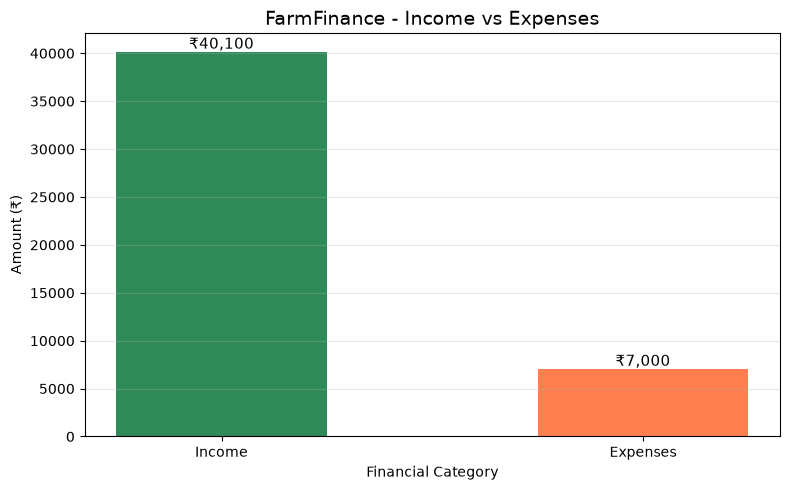

In [10]:
# Prepare financial data for visualization

categories = ["Income", "Expenses"]
amounts = [total_income, total_expenses]

# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    categories,
    amounts,
    color=["seagreen", "coral"],
    width=0.5
)

# Add values above bars
for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"₹{value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.title("FarmFinance - Income vs Expenses", fontsize=14)
plt.ylabel("Amount (₹)")
plt.xlabel("Financial Category")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

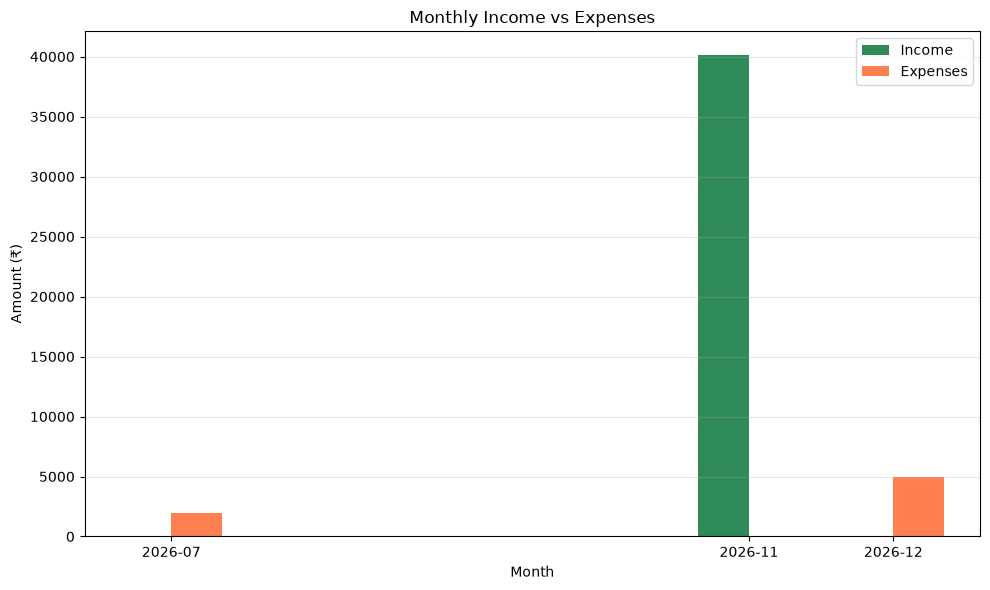

In [11]:
# Extract month from transaction date
transactions_clean["month"] = (
    transactions_clean["transaction_date"].dt.to_period("M")
)

# Calculate monthly income and expenses
monthly_data = transactions_clean.pivot_table(
    index="month",
    columns="transaction_type",
    values="amount",
    aggfunc="sum",
    fill_value=0
)

# Ensure both columns exist
monthly_data = monthly_data.reindex(
    columns=["Income", "Expense"],
    fill_value=0
)

# Plot monthly comparison
monthly_data.plot(
    kind="bar",
    figsize=(10, 6),
    color=["seagreen", "coral"],
    width=0.7
)

plt.title("Monthly Income vs Expenses")
plt.xlabel("Month")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=0)
plt.legend(["Income", "Expenses"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

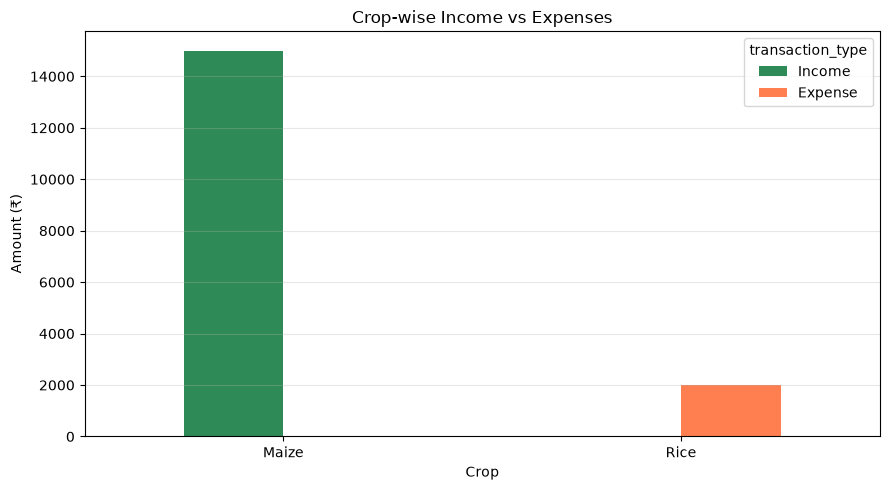

transaction_type,Income,Expense,Net Profit
crop_name,,,
Maize,15000.0,0.0,15000.0
Rice,0.0,2000.0,-2000.0


In [12]:
# Merge crop and transaction data
crop_analysis = transactions_clean.merge(
    crops_clean[["id", "crop_name"]],
    left_on="crop_id",
    right_on="id",
    how="inner"
)

# Calculate crop-wise income and expenses
crop_summary = crop_analysis.pivot_table(
    index="crop_name",
    columns="transaction_type",
    values="amount",
    aggfunc="sum",
    fill_value=0
)

crop_summary = crop_summary.reindex(
    columns=["Income", "Expense"],
    fill_value=0
)

crop_summary["Net Profit"] = (
    crop_summary["Income"] - crop_summary["Expense"]
)

# Plot crop-wise financial performance
crop_summary[["Income", "Expense"]].plot(
    kind="bar",
    figsize=(9, 5),
    color=["seagreen", "coral"]
)

plt.title("Crop-wise Income vs Expenses")
plt.xlabel("Crop")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Display profitability summary
display(crop_summary)

In [13]:
# Calculate profit margin
crop_summary["Profit Margin (%)"] = np.where(
    crop_summary["Income"] > 0,
    (crop_summary["Net Profit"] / crop_summary["Income"]) * 100,
    np.nan
)

# Display final crop profitability report
display(
    crop_summary.round(2)
)

transaction_type,Income,Expense,Net Profit,Profit Margin (%)
crop_name,,,,
Maize,15000.0,0.0,15000.0,100.0
Rice,0.0,2000.0,-2000.0,NaN


## Business Insights and Key Findings

### 1. Overall Financial Performance
- Total recorded income: ₹40,100
- Total recorded expenses: ₹7,000
- Overall recorded net profit: ₹33,100

### 2. Crop-wise Profitability
- Maize recorded a net profit of ₹15,000, with a recorded profit margin of 100%.
- Rice recorded a loss of ₹2,000 due to its recorded fertilizer expense of ₹2,000 and no associated income.

### 3. Monthly Financial Trends
- November 2026 recorded the highest income of ₹40,100.
- December 2026 recorded the highest monthly expenses of ₹5,000.
- July and December recorded negative monthly net results.

### 4. Expense Analysis
- Fertilizer accounted for 71.43% of recorded expenses.
- Rice Fertilizer accounted for 28.57%.

### 5. Data Quality Observations
- Two out of four transactions were not associated with a crop.
- No duplicate crop or transaction records were identified.
- Unlinked transactions limit the accuracy of crop-wise profitability comparisons.

### Conclusion
The analysis demonstrates how SQL and Python can be used together to examine agricultural financial performance, identify spending patterns and highlight data-quality issues. Further transaction classification and more complete crop-level records are needed for reliable profitability comparisons.

In [5]:
import pymysql
import os

try:
    test_connection = pymysql.connect(
        host=os.getenv("DB_HOST"),
        port=int(os.getenv("DB_PORT")),
        user=os.getenv("DB_USER"),
        password=os.getenv("DB_PASSWORD"),
        database=os.getenv("DB_NAME")
    )

    print("MySQL authentication successful!")
    test_connection.close()

except pymysql.MySQLError as error:
    print("MySQL authentication failed.")
    print("Error:", error.args[0], error.args[1])

MySQL authentication failed.
Error: 1045 Access denied for user 'root'@'localhost' (using password: YES)


In [9]:
crops_df = pd.read_sql("SELECT * FROM crops", engine)
transactions_df = pd.read_sql("SELECT * FROM transactions", engine)

display(crops_df)
display(transactions_df)

,id,crop_name,variety,season,area,area_unit,sowing_date,expected_harvest_date,status,created_at
0,1,Rice,Basmati,Kharif,2.0,Acres,2026-06-07,2026-12-25,Growing,2026-11-13 14:42:51
1,4,Maize,Hybrid,Kharif,2.0,Acres,2026-06-01,2026-10-15,Growing,2026-11-14 20:00:32


,id,transaction_type,description,amount,transaction_date,created_at,crop_id
0,1,Income,Wheat Sales,25100.0,2026-11-30,2026-11-13 14:00:03,NaN
1,2,Expense,Fertilizer,5000.0,2026-12-05,2026-11-13 14:00:43,NaN
2,4,Expense,Rice Fertilizer,2000.0,2026-07-07,2026-11-13 15:52:23,1.0
3,5,Income,Maize Sales,15000.0,2026-11-14,2026-11-14 20:08:52,4.0


In [11]:
# Calculate key financial metrics

total_income = transactions_df.loc[
    transactions_df["transaction_type"] == "Income", "amount"
].sum()

total_expenses = transactions_df.loc[
    transactions_df["transaction_type"] == "Expense", "amount"
].sum()

net_profit = total_income - total_expenses
total_transactions = len(transactions_df)
average_transaction = transactions_df["amount"].mean()

print("FARMFINANCE - FINANCIAL OVERVIEW")
print("--------------------------------")
print(f"Total Income: ₹{total_income:,.2f}")
print(f"Total Expenses: ₹{total_expenses:,.2f}")
print(f"Net Profit: ₹{net_profit:,.2f}")
print(f"Total Transactions: {total_transactions}")
print(f"Average Transaction: ₹{average_transaction:,.2f}")

FARMFINANCE - FINANCIAL OVERVIEW
--------------------------------
Total Income: ₹40,100.00
Total Expenses: ₹7,000.00
Net Profit: ₹33,100.00
Total Transactions: 4
Average Transaction: ₹11,775.00


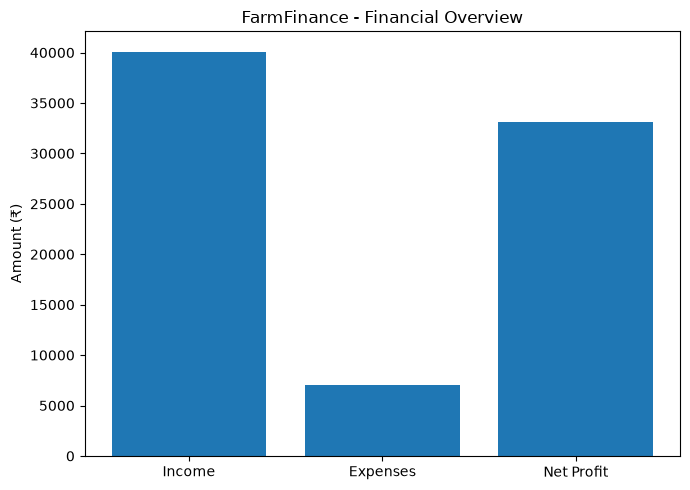

In [12]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Income", "Expenses", "Net Profit"],
    [total_income, total_expenses, net_profit]
)

plt.title("FarmFinance - Financial Overview")
plt.ylabel("Amount (₹)")
plt.tight_layout()
plt.show()

## Key Business Insights

1. **Overall Performance:** FarmFinance recorded ₹40,100 in income and ₹7,000 in expenses, resulting in a net balance of ₹33,100.

2. **Crop Performance:** Maize recorded a net profit of ₹15,000, while Rice recorded expenses of ₹2,000.

3. **Expense Analysis:** Fertilizer accounts for 71.43% of recorded expenses, making it the largest recorded expense category.

4. **Data Quality:** No duplicate records were identified. However, 2 out of 4 transactions are not linked to any crop.

5. **Recommendations:** Improve transaction-to-crop mapping and maintain consistent expense categorization to enable more accurate crop-wise financial analysis.

**Limitation:** These results reflect only the transactions currently recorded in the database. They should not be treated as complete farm profitability figures because some transactions are not linked to crops.